In [3]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_cohere import ChatCohere
from dotenv import load_dotenv

load_dotenv()

True

In [10]:
class LLMState(TypedDict):
    question: str
    answer: str

In [11]:
model = ChatCohere(
    model="command-a-03-2025",
    temperature=0.8
)

In [12]:
def generate_answer(state: LLMState) -> LLMState:
    question = state['question']
    prompt = f"answer the following question {question}"
    answer = model.invoke(prompt)
    state['answer'] = answer

    return state

In [2]:
graph = StateGraph(LLMState)

graph.add_node('generate_answer', generate_answer)
graph.add_edge(START, 'generate_answer')
graph.add_edge('generate_answer', END)

workflow = graph.compile()

NameError: name 'StateGraph' is not defined

In [ ]:
initial_state= {'question': 'who is nigga'}
workflow.invoke(initial_state)

{'question': 'who is nigga',
 'answer': AIMessage(content='The term "nigga" is a colloquial and often controversial word that has evolved in its usage and meaning, particularly within African American Vernacular English (AAVE). Here’s a breakdown of its context and usage:\n\n1. **Historical Origin**: The term "nigga" is derived from the highly offensive racial slur "nigger," which has deep roots in racism and slavery. "Nigger" was used historically to dehumanize and demean Black people.\n\n2. **Reclamation and Modern Usage**: In contemporary contexts, particularly within the African American community, "nigga" has been reclaimed as a term of endearment or solidarity among peers. It is often used informally among friends or within specific cultural and social circles.\n\n3. **Cultural Sensitivity**: While "nigga" may be used casually within certain communities, it is important to recognize that its usage is highly context-dependent. Non-Black individuals using the term is generally cons

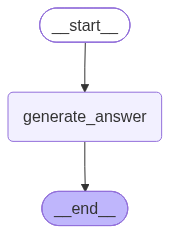

In [15]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())